### Exporitary Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
import re
# plt.style.use('ggplot')

In [2]:
df = pd.read_csv("amazon_products_sales_data_uncleaned.csv")

#### Step 1: Data Understanding
- Dataframe shape
- head and tail
- dtypes
- describe
- info

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   title                     42675 non-null  object
 1   rating                    41651 non-null  object
 2   number_of_reviews         41651 non-null  object
 3   bought_in_last_month      39458 non-null  object
 4   current/discounted_price  30926 non-null  object
 5   price_on_variant          42675 non-null  object
 6   listed_price              42675 non-null  object
 7   is_best_seller            42675 non-null  object
 8   is_sponsored              42675 non-null  object
 9   is_couponed               42675 non-null  object
 10  buy_box_availability      28022 non-null  object
 11  delivery_details          30955 non-null  object
 12  sustainability_badges     3408 non-null   object
 13  image_url                 42675 non-null  object
 14  product_url           

In [4]:
df.head(3)

,title,rating,number_of_reviews,bought_in_last_month,current/discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
0,BOYA BOYALINK 2 Wireless Lavalier Microphone f...,4.6 out of 5 stars,375,300+ bought in past month,89.68,basic variant price: 2.4GHz,$159.00,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Mon, Sep 1",Carbon impact,https://m.media-amazon.com/images/I/71pAqiVEs3...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,2025-08-21 11:14:29
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Ch...",4.3 out of 5 stars,"2,457",6K+ bought in past month,9.99,basic variant price: nan,$15.99,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Fri, Aug 29",NaN,https://m.media-amazon.com/images/I/61nbF6aVIP...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,2025-08-21 11:14:29
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wirel...",4.6 out of 5 stars,"3,044",2K+ bought in past month,314.00,basic variant price: nan,$349.00,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Mon, Sep 1",NaN,https://m.media-amazon.com/images/I/61h78MEXoj...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,2025-08-21 11:14:29


In [5]:
df.describe()

,title,rating,number_of_reviews,bought_in_last_month,current/discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
count,42675,41651,41651,39458,30926,42675,42675,42675,42675,42675,28022,30955,3408,42675,40606,42675
unique,8808,31,4413,59,2576,3466,911,12,2,42,1,298,16,8038,40606,1559
top,"Duracell Coppertop 9V Battery, 6 Count (Pack o...",4.6 out of 5 stars,25,100+ bought in past month,29.99,basic variant price: nan,No Discount,No Badge,Organic,No Coupon,Add to cart,"Delivery Mon, Sep 1",Small Business,https://m.media-amazon.com/images/I/51Xr76m2WL...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,2025-08-21 11:15:31
freq,744,6151,626,8801,825,21031,30364,40814,35664,40727,28022,6189,1341,1461,1,33


#### Step 2: Data Preperation
- Dropping irrelevant columns and rows
- Identifying duplicated columns
- Renameing Columns
- Feature Creation

In [6]:
# drop unwanted columns
df.drop(columns=['image_url', 'product_url', 'collected_at'], inplace=True)

In [7]:
df['number_of_reviews'] = pd.to_numeric(df['number_of_reviews'].str.replace(',', ''))

In [8]:
df['rating'] = pd.to_numeric(df['rating'].str.slice(0, 3))

In [9]:
df['is_sponsored'] = df['is_sponsored'].replace(['Organic', 'Sponsored'], [False, True])

C:\Users\learn\AppData\Local\Temp\ipykernel_3976\690644713.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['is_sponsored'] = df['is_sponsored'].replace(['Organic', 'Sponsored'], [False, True])


In [10]:
df['buy_box_availability'] = df['buy_box_availability'].replace("Add to cart", True)
df['buy_box_availability'] = df['buy_box_availability'].fillna(False)

C:\Users\learn\AppData\Local\Temp\ipykernel_3976\344494731.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['buy_box_availability'] = df['buy_box_availability'].fillna(False)


In [11]:
df["listed_price"] = df["listed_price"].replace("No Discount", None)
df["listed_price"] = df["listed_price"].str.replace(r"[$,]", "", regex=True)
df["listed_price"] = pd.to_numeric(df["listed_price"])

In [12]:
df['current/discounted_price'] = pd.to_numeric(df['current/discounted_price'].str.replace(',', ''))

In [13]:
updated_col = df["bought_in_last_month"].map(lambda s: type(s) == type("") and s.endswith("+ bought in past month") and s.replace("+ bought in past month", "").replace("K", "000") or None)
df["bought_in_last_month"] = pd.to_numeric(updated_col)

In [14]:
price_patten = re.compile(r"^\$\d+(,\d{2,3})*(\.\d{1,2})*$")
updated_col = df['price_on_variant'].map(lambda s: s[21:])
updated_col = updated_col.map(lambda s: s[1:].replace(",", "") if re.fullmatch(price_patten, s) else None)
df['price_on_variant'] = pd.to_numeric(updated_col)

In [15]:
# Rename Columns

df.rename(columns={
    "title": "Title",
    "rating": "Rating",
    "number_of_reviews": "Number_Of_Reviews",
    "bought_in_last_month": "Orders_In_Last_Month",
    "price_on_variant": "Price_On_Variant",
    "listed_price": "Listed_Price",
    "current/discounted_price": "Discounted_Price",
    "is_best_seller": "Best_Seller_Badge",
    "is_sponsored": "Is_Sponsored",
    "is_couponed": "Is_Couponed",
    "buy_box_availability": "Is_ATC_Btn_Available",
    "delivery_details": "Delivery_Details",
    "sustainability_badges": "Sustainability_Badges"
}, inplace=True)

In [16]:
# combine price_on_variant column with listed_price

listed_price = df["Listed_Price"]
price_on_variant = df["Price_On_Variant"]
discounted_price = df["Discounted_Price"]

listed_price = listed_price.combine(price_on_variant, lambda v1, v2: v1 if v1 == v1 else v2)
listed_price = listed_price.combine(discounted_price, lambda v1, v2: v1 if v1 == v1 else v2)
discounted_price = discounted_price.combine(listed_price, lambda v1, v2: v1 if v1 == v1 else v2)

df["Discounted_Price"] = discounted_price
df["Listed_Price"] = listed_price

df.drop(columns=["Price_On_Variant"], inplace=True)


#### Step 3: Feature Understanding
(Univariate Analysis)
- Plotting Feature Distributions:
- Histogram
- KDE
- Boxplot

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42675 entries, 0 to 42674
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Title                  42675 non-null  object 
 1   Rating                 41651 non-null  float64
 2   Number_Of_Reviews      41651 non-null  float64
 3   Orders_In_Last_Month   32164 non-null  float64
 4   Discounted_Price       40613 non-null  float64
 5   Listed_Price           40613 non-null  float64
 6   Best_Seller_Badge      42675 non-null  object 
 7   Is_Sponsored           42675 non-null  bool   
 8   Is_Couponed            42675 non-null  object 
 9   Is_ATC_Btn_Available   42675 non-null  bool   
 10  Delivery_Details       30955 non-null  object 
 11  Sustainability_Badges  3408 non-null   object 
dtypes: bool(2), float64(5), object(5)
memory usage: 3.3+ MB


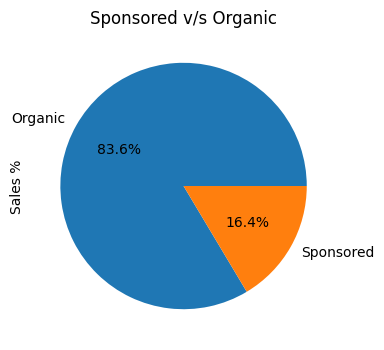

In [18]:
# Sponsored v/s Organic sales

data = df.groupby("Is_Sponsored")["Is_Sponsored"].count()
data.plot(kind="pie", y="Is_Sponsored", ylabel="Sales %", title="Sponsored v/s Organic", autopct="%1.1f%%", labels=["Organic", "Sponsored"], figsize=(4,4))
plt.show()

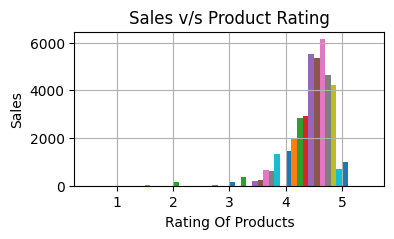

In [19]:
data = df.groupby("Rating")["Rating"]
graph = data.plot(kind="hist", xlabel="Rating Of Products", ylabel="Sales", title="Sales v/s Product Rating", grid=True, figsize=(4, 2))

#### Step 4: Feature Relationships
- scatterplot
- Heatmap Correlation
- Pairplot
- Groupby comparisons

<Axes: >

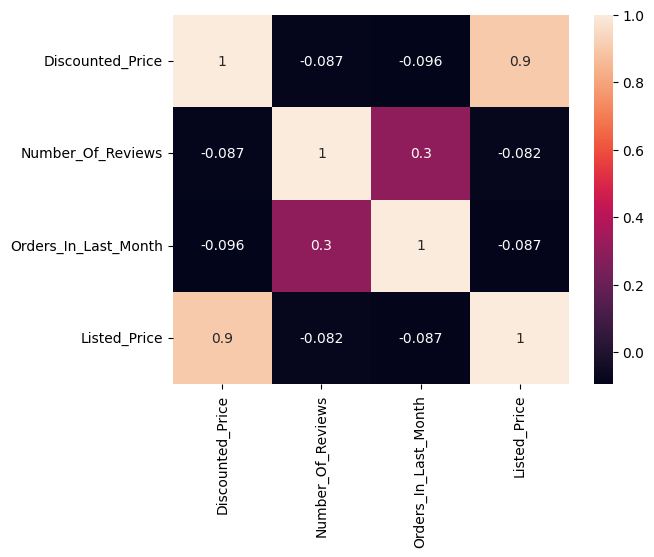

In [20]:
df_corr = df[['Discounted_Price', 'Number_Of_Reviews', 'Orders_In_Last_Month', 'Listed_Price']].dropna().corr()
sns.heatmap(df_corr, annot=True)

In [21]:
df.to_csv("amazon_products_sales_data_cleaned.csv", sep='\t', index=False)